In [1]:
import sys
sys.path.insert(0, '..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Reload the rider module to pick up any changes
import importlib
import app.rider
importlib.reload(app.rider)
from app.rider import Rider

%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid')

## 1. Create a Rider Profile

The `Rider` class calculates Critical Power (CP) and W' (anaerobic capacity) using one of three methods:

### Method A: Profile Estimation
If you know your CP and rider type, W' is estimated from typical profiles.
- **rider_type**: "time_trialist", "sprinter", or "all_rounder"
- **critical_power**: Your critical power in watts

### Method B: Manual Best Efforts
Provide your own power-duration data for curve fitting.
- **best_efforts**: Dict of `{duration_seconds: power_watts}` e.g., `{60: 400, 300: 320, 1200: 270}`

### Method C: Strava API (default)
Automatically fetches your best efforts from Strava. Results are cached in a local database.
- **days**: Number of days to look back (default 60)
- Requires Strava authentication

### Physical Parameters (all methods)
- **height**: Rider height in meters (for CdA estimation)
- **weight**: Total mass in kg (rider + bike + gear)
- **bike_type**: "Road", "TT", "Gravel", or "MTB"
- **position**: "Hoods", "Drops", "Aero", or "Flat"

In [2]:
# Common rider parameters used across all examples
RIDER_HEIGHT = 1.80  # meters
RIDER_WEIGHT = 75    # kg (body weight)
BIKE_WEIGHT = 8      # kg
GEAR_WEIGHT = 2      # kg (bottles, tools, etc.)
TOTAL_WEIGHT = RIDER_WEIGHT + BIKE_WEIGHT + GEAR_WEIGHT

print(f"Physical Parameters:")
print(f"  Height: {RIDER_HEIGHT} m")
print(f"  Body weight: {RIDER_WEIGHT} kg")
print(f"  Total weight: {TOTAL_WEIGHT} kg (rider + bike + gear)")

Physical Parameters:
  Height: 1.8 m
  Body weight: 75 kg
  Total weight: 85 kg (rider + bike + gear)


In [3]:
# =============================================================================
# METHOD A: Profile Estimation (rider_type + critical_power)
# =============================================================================
# Use this when you know your Critical Power (e.g., from a test or ~95% of FTP)
# The Rider class will estimate W' based on typical profiles for your rider type

FTP = 280  # Functional Threshold Power (from testing)
MY_CRITICAL_POWER = int(FTP * 0.95)  # CP is typically ~95% of FTP

rider_method_a = Rider(
    height=RIDER_HEIGHT,
    weight=TOTAL_WEIGHT,
    bike_type="Road",
    position="Hoods",
    rider_type="all_rounder",  # Options: "time_trialist", "sprinter", "all_rounder"
    critical_power=MY_CRITICAL_POWER
)

print("METHOD A: Profile Estimation")
print(f"  Input: rider_type='all_rounder', critical_power={MY_CRITICAL_POWER}W")
print(f"  Result: CP={rider_method_a.critical_power:.0f}W, W'={rider_method_a.WTank:,.0f}J")
print(f"  CdA: {rider_method_a.CdA} m²")
print(f"\n  Estimated best efforts: {rider_method_a.best_efforts}")

Method A: Estimating W' from rider profile (all_rounder) and CP (266W)
METHOD A: Profile Estimation
  Input: rider_type='all_rounder', critical_power=266W
  Result: CP=266W, W'=15,160J
  CdA: 0.36 m²

  Estimated best efforts: {60: 425.6, 300: 345.8, 600: 305.9, 1200: 287.28000000000003, 1800: 273.98, 3600: 266.0}


In [4]:
# =============================================================================
# METHOD B: Manual Best Efforts
# =============================================================================
# Use this when you have power data from specific efforts (e.g., from a power meter)
# The Rider class will fit the CP model to your data

my_best_efforts = {
    30: 650,    # 30 second sprint
    60: 480,    # 1 minute effort
    120: 380,   # 2 minute effort
    300: 320,   # 5 minute effort (typical VO2max test)
    1200: 275,  # 20 minute effort
    1800: 265,  # 30 minute effort
}

rider_method_b = Rider(
    height=RIDER_HEIGHT,
    weight=TOTAL_WEIGHT,
    bike_type="Road",
    position="Drops",
    best_efforts=my_best_efforts
)

print("METHOD B: Manual Best Efforts")
print(f"  Input: best_efforts = {my_best_efforts}")
print(f"  Result: CP={rider_method_b.critical_power:.0f}W, W'={rider_method_b.WTank:,.0f}J")
print(f"  CdA: {rider_method_b.CdA} m²")

Method B: Calculating CP and W' from provided best efforts
METHOD B: Manual Best Efforts
  Input: best_efforts = {30: 650, 60: 480, 120: 380, 300: 320, 1200: 275, 1800: 265}
  Result: CP=273W, W'=11,599J
  CdA: 0.339 m²


In [5]:
# =============================================================================
# METHOD C: Strava API (requires authentication)
# =============================================================================
# This is the default method - just provide physical parameters and the class
# will automatically fetch your best power efforts from Strava.
# The workflow is:
#   1. Get rider_id from Strava athlete ID
#   2. Check local database for cached CP/W' data
#   3. If no cache, fetch best efforts from Strava API (last N days)
#   4. Fit CP model and cache results for future use
#
# NOTE: If you get a 401 error, your Strava token may not have the required scopes.
# Required scopes: activity:read_all (to read activity power data)
# Re-authorize at: https://www.strava.com/oauth/authorize?client_id=YOUR_ID&response_type=code&redirect_uri=http://localhost&scope=read,activity:read_all

try:
    rider_method_c = Rider(
        height=RIDER_HEIGHT,
        weight=TOTAL_WEIGHT,
        bike_type="Road",
        position="Hoods",
        days=90  # Look back 90 days for best efforts
    )

    print("\nMETHOD C: Strava API")
    if rider_method_c.critical_power and rider_method_c.WTank:
        print(f"  Result: CP={rider_method_c.critical_power:.0f}W, W'={rider_method_c.WTank:,.0f}J")
        print(f"  CdA: {rider_method_c.CdA} m²")
        print(f"  Best efforts: {rider_method_c.best_efforts}")
    else:
        print("  Could not calculate CP/W' - see error messages above")
        print("\n  If you got a 401 error on activities, your token may lack 'activity:read_all' scope.")
        print("  To fix: Re-authorize your Strava app with the correct scopes.")
        
except Exception as e:
    print(f"\nMETHOD C: Strava API - Error: {e}")
    print("  Falling back to Method A or B for this demo.")

Got Strava athlete ID: 186207
Method C: Fetching best efforts from Strava (last 90 days)...
Calculated and cached: CP=383W, W'=9977J

METHOD C: Strava API
  Result: CP=383W, W'=9,977J
  CdA: 0.36 m²
  Best efforts: {30: 664.4666666666667, 60: 647.3333333333334, 120: 486.325, 300: 403.98, 1200: 365.9125, 1800: 361.15777777777777}


Fitted CP Model Parameters:
  Critical Power (CP): 273.1 W
  W' (anaerobic capacity): 11,599 J (11.6 kJ)


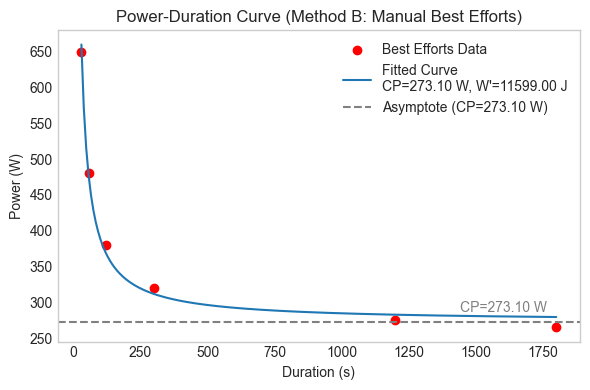

In [6]:
# Visualize the power-duration curve fit from Method B
# The WTankCalculator can plot the fitted curve against your data

print(f"Fitted CP Model Parameters:")
print(f"  Critical Power (CP): {rider_method_b.critical_power:.1f} W")
print(f"  W' (anaerobic capacity): {rider_method_b.WTank:,.0f} J ({rider_method_b.WTank/1000:.1f} kJ)")

# Plot the power-duration curve
if rider_method_b.WTank_calculator:
    fig = rider_method_b.WTank_calculator.plot_power_duration_curve()
    plt.title("Power-Duration Curve (Method B: Manual Best Efforts)")
    plt.tight_layout()
    plt.show()

In [7]:
# =============================================================================
# Select which rider to use for the rest of the notebook
# =============================================================================
# Choose from rider_method_a (profile), rider_method_b (manual), or rider_method_c (Strava)

rider = rider_method_b  # Using manual best efforts for this demo

# Set up variables for downstream cells
CRITICAL_POWER = int(rider.critical_power)
W_PRIME = int(rider.WTank)
FTP = int(CRITICAL_POWER / 0.95)  # Back-calculate FTP from CP

print(f"Selected Rider: {rider}")
print(f"\nVariables for downstream analysis:")
print(f"  CRITICAL_POWER = {CRITICAL_POWER} W")
print(f"  W_PRIME = {W_PRIME:,} J")
print(f"  FTP (estimated) = {FTP} W")

Selected Rider: Rider: 1.8m, 85kg, Bike: Road, Position: Drops, Estimated CdA: 0.339 m^2, Critical Power: 273.1030996669969 W, WTank: 11.6 kJ

Variables for downstream analysis:
  CRITICAL_POWER = 273 W
  W_PRIME = 11,599 J
  FTP (estimated) = 287 W


## 2. Critical Power Model

The 2-parameter critical power model:
$$P(t) = CP + \frac{W'}{t}$$

Where:
- $P(t)$ = power sustainable for time $t$
- $CP$ = critical power (watts)
- $W'$ = anaerobic work capacity (joules)
- $t$ = time (seconds)

In [8]:
def power_for_duration(duration_sec, cp, w_prime):
    """Calculate max sustainable power for a given duration."""
    return cp + (w_prime / duration_sec)

def duration_at_power(power, cp, w_prime):
    """Calculate how long you can sustain a given power."""
    if power <= cp:
        return float('inf')  # Sustainable indefinitely
    return w_prime / (power - cp)

# Test some key durations
test_durations = [
    (60, "1 min"),
    (180, "3 min"),
    (300, "5 min"),
    (600, "10 min"),
    (1200, "20 min"),
    (3600, "60 min")
]

print("Power-Duration Curve:")
for dur_sec, label in test_durations:
    power = power_for_duration(dur_sec, CRITICAL_POWER, W_PRIME)
    print(f"  {label:>8}: {power:.0f} W ({power/RIDER_WEIGHT:.1f} W/kg)")

Power-Duration Curve:
     1 min: 466 W (6.2 W/kg)
     3 min: 337 W (4.5 W/kg)
     5 min: 312 W (4.2 W/kg)
    10 min: 292 W (3.9 W/kg)
    20 min: 283 W (3.8 W/kg)
    60 min: 276 W (3.7 W/kg)


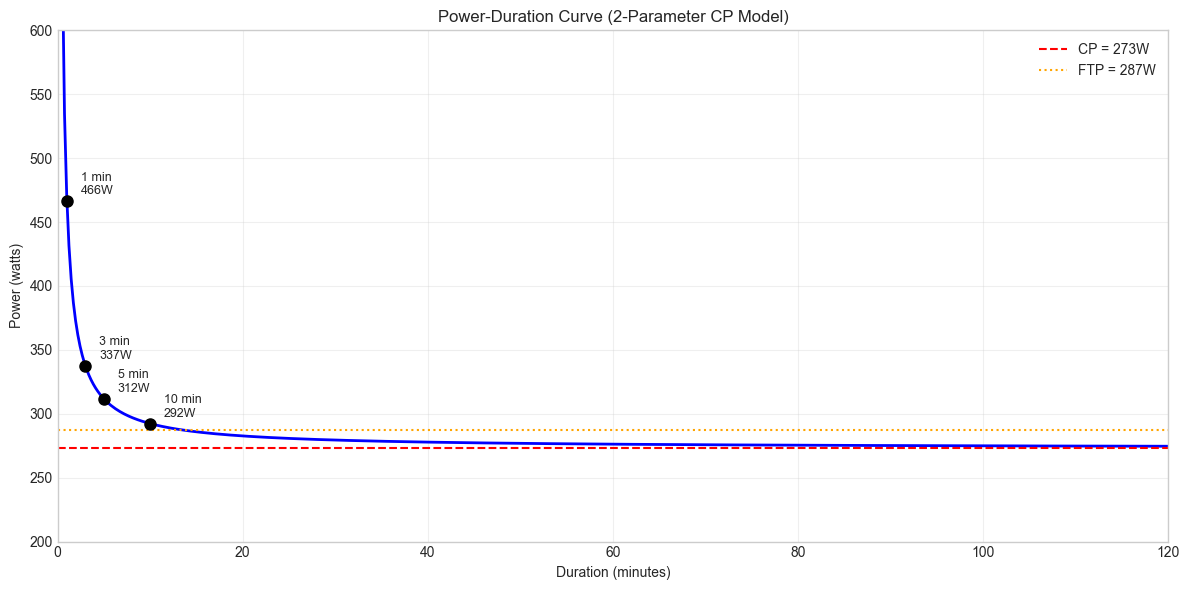

In [9]:
# Plot power-duration curve
durations = np.linspace(30, 7200, 500)  # 30 sec to 2 hours
powers = [power_for_duration(d, CRITICAL_POWER, W_PRIME) for d in durations]

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(durations/60, powers, 'b-', linewidth=2)
ax.axhline(y=CRITICAL_POWER, color='red', linestyle='--', label=f'CP = {CRITICAL_POWER}W')
ax.axhline(y=FTP, color='orange', linestyle=':', label=f'FTP = {FTP}W')

# Mark key points
for dur_sec, label in test_durations[:4]:
    power = power_for_duration(dur_sec, CRITICAL_POWER, W_PRIME)
    ax.plot(dur_sec/60, power, 'ko', markersize=8)
    ax.annotate(f'{label}\n{power:.0f}W', (dur_sec/60, power), 
                textcoords='offset points', xytext=(10, 5), fontsize=9)

ax.set_xlabel('Duration (minutes)')
ax.set_ylabel('Power (watts)')
ax.set_title('Power-Duration Curve (2-Parameter CP Model)')
ax.set_xlim(0, 120)
ax.set_ylim(200, 600)
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 3. W' Depletion and Recovery

When riding above CP, W' depletes. Below CP, it recovers.

**Depletion rate**: $\frac{dW'}{dt} = CP - P$ (negative when P > CP)

**Recovery**: Exponential recovery with time constant τ (~550s typical)

In [10]:
def simulate_w_prime(powers, durations, cp, w_prime_max, tau=550):
    """
    Simulate W' depletion and recovery.
    
    Args:
        powers: List of power values
        durations: List of duration for each power (seconds)
        cp: Critical power
        w_prime_max: Starting W'
        tau: Recovery time constant
    
    Returns:
        List of W' values at each time point
    """
    w_prime_current = w_prime_max
    w_prime_history = [w_prime_current]
    times = [0]
    
    t = 0
    for power, duration in zip(powers, durations):
        # For each second in this interval
        for _ in range(int(duration)):
            t += 1
            if power > cp:
                # Depletion
                w_prime_current -= (power - cp)
            else:
                # Recovery (simplified exponential)
                recovery_rate = (w_prime_max - w_prime_current) / tau
                w_prime_current += recovery_rate
            
            w_prime_current = max(0, min(w_prime_max, w_prime_current))
            w_prime_history.append(w_prime_current)
            times.append(t)
    
    return times, w_prime_history

# Simulate a sample effort: hard start, then settle
effort_powers = [350, 300, 250, 320, 240, 280]
effort_durations = [60, 120, 180, 90, 300, 60]  # seconds each

times, w_prime_values = simulate_w_prime(
    effort_powers, effort_durations, CRITICAL_POWER, W_PRIME
)

print(f"W' simulation:")
print(f"  Started at: {W_PRIME:,} J")
print(f"  Minimum: {min(w_prime_values):,.0f} J ({min(w_prime_values)/W_PRIME*100:.0f}%)")
print(f"  Final: {w_prime_values[-1]:,.0f} J ({w_prime_values[-1]/W_PRIME*100:.0f}%)")

W' simulation:
  Started at: 11,599 J
  Minimum: 1,705 J (15%)
  Final: 5,447 J (47%)


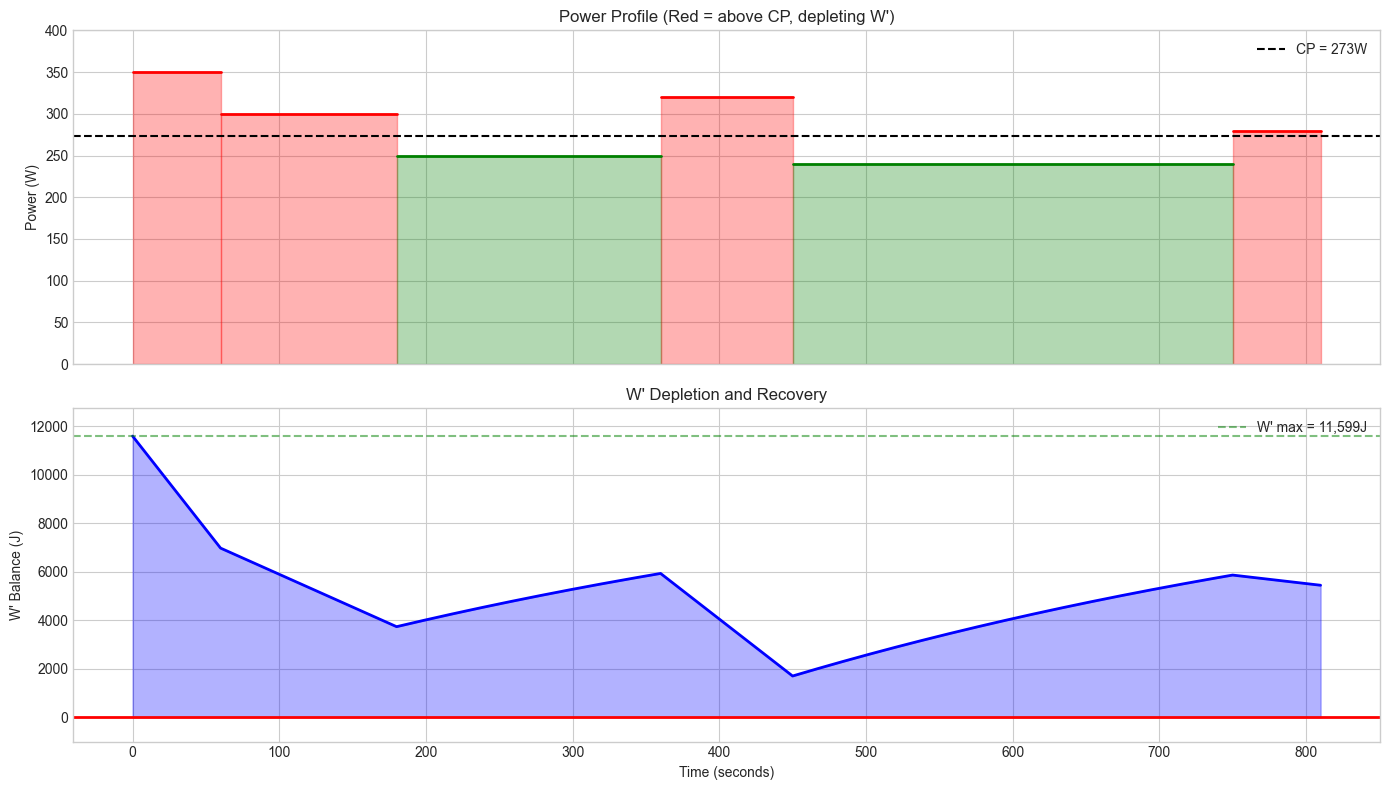

In [11]:
# Plot W' depletion
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

# Power profile
t = 0
for power, duration in zip(effort_powers, effort_durations):
    color = 'red' if power > CRITICAL_POWER else 'green'
    ax1.fill_between([t, t+duration], 0, power, alpha=0.3, color=color)
    ax1.plot([t, t+duration], [power, power], color=color, linewidth=2)
    t += duration

ax1.axhline(y=CRITICAL_POWER, color='black', linestyle='--', label=f'CP = {CRITICAL_POWER}W')
ax1.set_ylabel('Power (W)')
ax1.set_title('Power Profile (Red = above CP, depleting W\')')
ax1.legend()
ax1.set_ylim(0, 400)

# W' balance
ax2.fill_between(times, 0, w_prime_values, alpha=0.3, color='blue')
ax2.plot(times, w_prime_values, 'b-', linewidth=2)
ax2.axhline(y=W_PRIME, color='green', linestyle='--', alpha=0.5, label=f'W\' max = {W_PRIME:,}J')
ax2.axhline(y=0, color='red', linestyle='-', linewidth=2)

ax2.set_xlabel('Time (seconds)')
ax2.set_ylabel('W\' Balance (J)')
ax2.set_title('W\' Depletion and Recovery')
ax2.legend()
ax2.set_ylim(-1000, W_PRIME * 1.1)

plt.tight_layout()
plt.show()

## 4. Aerodynamic Drag (CdA)

CdA = Drag coefficient × Frontal area

Typical values:
- **Upright/hoods**: 0.35-0.40 m²
- **Drops**: 0.30-0.35 m²
- **Aero position**: 0.25-0.30 m²
- **TT position**: 0.20-0.25 m²

In [12]:
def estimate_cda(height_m, weight_kg, position='drops'):
    """
    Estimate CdA based on rider size and position.
    Uses empirical formulas from cycling literature.
    """
    # Frontal area estimation (Heil, 2001 approximation)
    bsa = 0.00949 * (height_m * 100) ** 0.655 * weight_kg ** 0.441  # Body surface area
    
    # Position multipliers for frontal area
    position_factors = {
        'upright': 0.35,
        'hoods': 0.32,
        'drops': 0.28,
        'aero': 0.24,
        'tt': 0.21
    }
    
    factor = position_factors.get(position, 0.30)
    frontal_area = bsa * factor
    
    # Drag coefficient (fairly constant ~0.7-0.9)
    cd = 0.80
    
    return cd * frontal_area

# Compare positions using RIDER_HEIGHT from earlier cell
positions = ['upright', 'hoods', 'drops', 'aero', 'tt']

print(f"CdA estimates for {RIDER_HEIGHT}m, {RIDER_WEIGHT}kg rider:")
for pos in positions:
    cda = estimate_cda(RIDER_HEIGHT, RIDER_WEIGHT, pos)
    print(f"  {pos:>8}: {cda:.3f} m²")

# Compare with Rider class CdA estimate
if 'rider' in dir():
    print(f"\nRider class CdA ({rider.position}): {rider.CdA:.3f} m²")

CdA estimates for 1.8m, 75kg rider:
   upright: 0.535 m²
     hoods: 0.489 m²
     drops: 0.428 m²
      aero: 0.367 m²
        tt: 0.321 m²

Rider class CdA (Drops): 0.339 m²


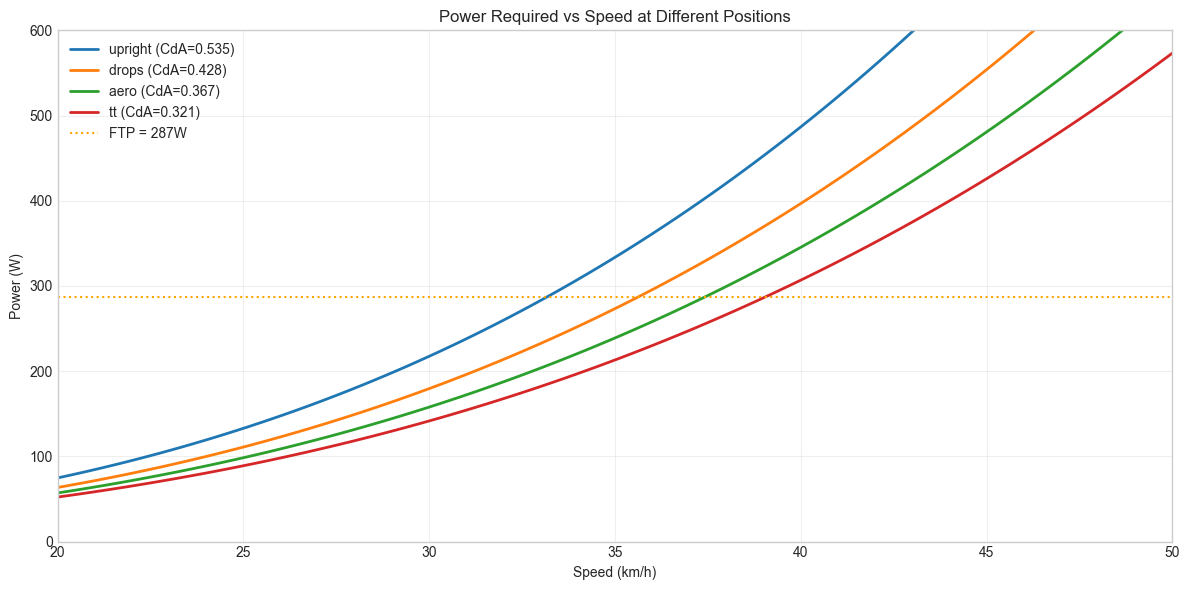

In [13]:
def power_for_speed(speed_mps, cda, crr, weight, grade=0):
    """
    Calculate power required for given speed.
    
    Args:
        speed_mps: Speed in m/s
        cda: Drag coefficient × frontal area (m²)
        crr: Rolling resistance coefficient
        weight: Total mass in kg
        grade: Gradient as decimal (0.05 = 5%)
    """
    rho = 1.225  # Air density kg/m³
    g = 9.81     # Gravity m/s²
    
    # Aerodynamic drag
    p_aero = 0.5 * rho * cda * speed_mps ** 3
    
    # Rolling resistance
    p_roll = crr * weight * g * speed_mps
    
    # Gravity (climbing)
    p_gravity = weight * g * grade * speed_mps
    
    return p_aero + p_roll + p_gravity

# Power vs speed at different CdA values
speeds_kph = np.linspace(20, 50, 100)
speeds_mps = speeds_kph / 3.6

fig, ax = plt.subplots(figsize=(12, 6))

CRR = 0.004  # Typical road tire

for pos in ['upright', 'drops', 'aero', 'tt']:
    cda = estimate_cda(RIDER_HEIGHT, RIDER_WEIGHT, pos)
    powers = [power_for_speed(s, cda, CRR, TOTAL_WEIGHT) for s in speeds_mps]
    ax.plot(speeds_kph, powers, linewidth=2, label=f'{pos} (CdA={cda:.3f})')

ax.axhline(y=FTP, color='orange', linestyle=':', label=f'FTP = {FTP}W')

ax.set_xlabel('Speed (km/h)')
ax.set_ylabel('Power (W)')
ax.set_title('Power Required vs Speed at Different Positions')
ax.legend()
ax.grid(True, alpha=0.3)
ax.set_xlim(20, 50)
ax.set_ylim(0, 600)

plt.tight_layout()
plt.show()

## 5. Grade Effects on Power

At steep gradients, gravity dominates; aero becomes less important.

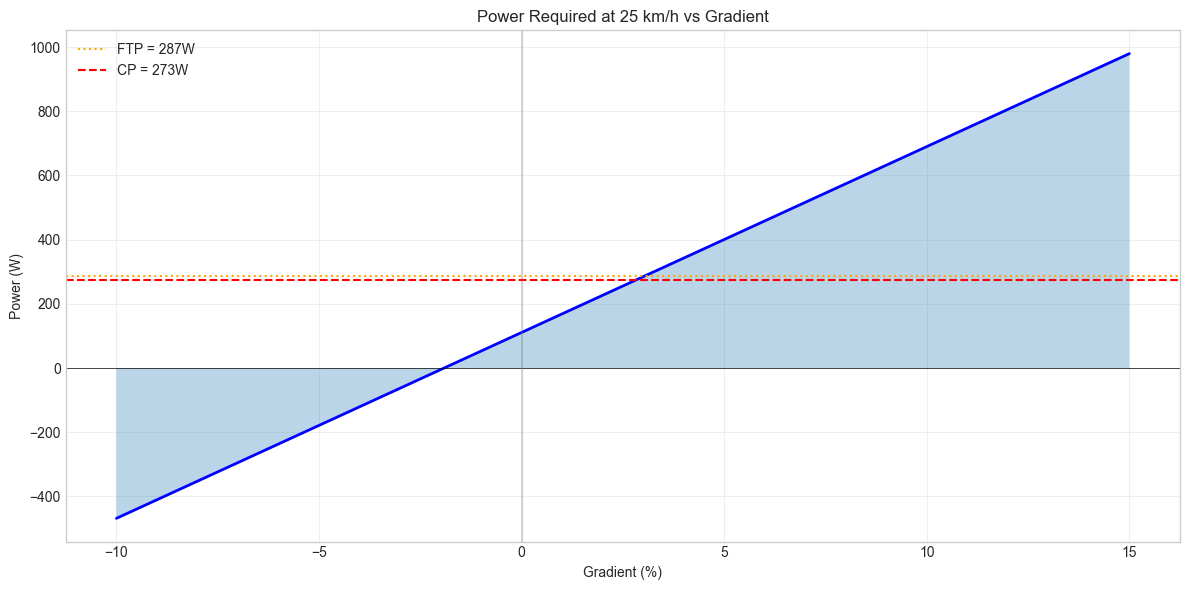

In [14]:
# Power required at constant speed across different gradients
CONSTANT_SPEED = 25 / 3.6  # 25 km/h in m/s
CDA = estimate_cda(RIDER_HEIGHT, RIDER_WEIGHT, 'drops')

gradients = np.linspace(-10, 15, 100)  # -10% to +15%
powers = [power_for_speed(CONSTANT_SPEED, CDA, CRR, TOTAL_WEIGHT, g/100) for g in gradients]

fig, ax = plt.subplots(figsize=(12, 6))

ax.fill_between(gradients, 0, powers, alpha=0.3)
ax.plot(gradients, powers, 'b-', linewidth=2)
ax.axhline(y=0, color='black', linewidth=0.5)
ax.axhline(y=FTP, color='orange', linestyle=':', label=f'FTP = {FTP}W')
ax.axhline(y=CRITICAL_POWER, color='red', linestyle='--', label=f'CP = {CRITICAL_POWER}W')
ax.axvline(x=0, color='gray', linestyle='-', alpha=0.3)

ax.set_xlabel('Gradient (%)')
ax.set_ylabel('Power (W)')
ax.set_title(f'Power Required at {CONSTANT_SPEED*3.6:.0f} km/h vs Gradient')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

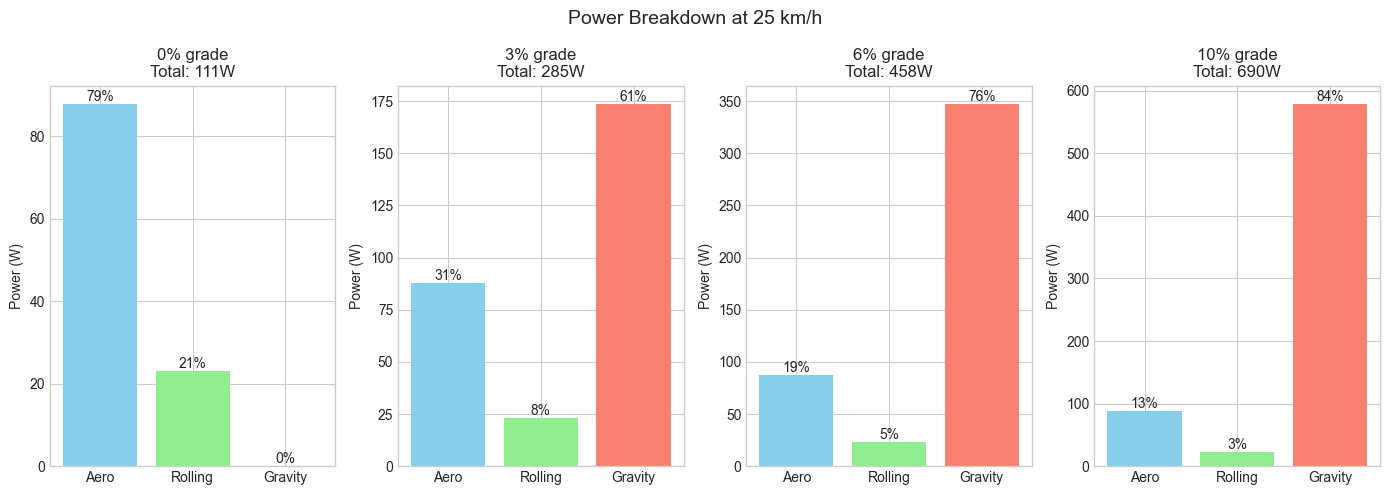

In [15]:
# Power breakdown at different gradients
test_gradients = [0, 3, 6, 10]

fig, axes = plt.subplots(1, len(test_gradients), figsize=(14, 5))

rho = 1.225
g = 9.81

for ax, grade in zip(axes, test_gradients):
    speed = CONSTANT_SPEED
    
    p_aero = 0.5 * rho * CDA * speed ** 3
    p_roll = CRR * TOTAL_WEIGHT * g * speed
    p_gravity = TOTAL_WEIGHT * g * (grade/100) * speed
    
    components = [p_aero, p_roll, p_gravity]
    labels = ['Aero', 'Rolling', 'Gravity']
    colors = ['skyblue', 'lightgreen', 'salmon']
    
    ax.bar(labels, components, color=colors)
    ax.set_title(f'{grade}% grade\nTotal: {sum(components):.0f}W')
    ax.set_ylabel('Power (W)')
    
    # Show percentages
    total = sum(components)
    for i, (comp, lbl) in enumerate(zip(components, labels)):
        ax.annotate(f'{comp/total*100:.0f}%', (i, comp), 
                   ha='center', va='bottom', fontsize=10)

plt.suptitle(f'Power Breakdown at {CONSTANT_SPEED*3.6:.0f} km/h', fontsize=14)
plt.tight_layout()
plt.show()

## 6. Key Takeaways

- **CP and W'** define your power-duration relationship
- **W' depletion** limits hard efforts; recovery happens below CP
- **CdA** matters most on flat/fast sections
- **Weight** matters most on climbs
- Optimal pacing considers when to spend W' based on terrain